# EJERCICIOS

In [1]:
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA
from sklearn.linear_model import SGDClassifier
from matplotlib import pyplot as plt
from sklearn.manifold import LocallyLinearEmbedding, MDS, TSNE
from sklearn.pipeline import make_pipeline

## EJERCICIO 1

Carga el conjunto de datos MNIST y divídelo en un conjunto de entrenamiento y un conjunto de prueba (coge las 60.000 primeras instancias para el entrenamiento y las 10.000 restantes para la prueba). 
Entrena un clasificador random forest en el conjunto de datos y cronometra cuánto tarda (puedes usar la anotación %time de jupyter notebook); luego, evalúa el modelo resultante en el conjunto de prueba. 

A continuación, utiliza PCA para reducir la dimensionalidad del conjunto de datos, con un ratio de varianza explicada del 95%. Entrena un nuevo clasificador random forest en el conjunto de datos reducido y comprueba cuánto tarda. ¿Ha sido el entrenamiento mucho más rápido? A continuación, evalúa el clasificador en el conjunto de prueba. ¿Qué tal lo hace en comparación con el clasificador anterior? 

Prueba otra vez con un SGDClassifier, ¿cuánto ayuda ahora el PCA?

In [2]:
mnist = fetch_openml('mnist_784', as_frame=False)

X_train, y_train = mnist.data[:60_000], mnist.target[:60_000]
X_test, y_test = mnist.data[60_000:], mnist.target[60_000:]

print(X_train.shape, X_test.shape)

(60000, 784) (10000, 784)


In [ ]:
random_forest = RandomForestClassifier(n_jobs=-1)

%time random_forest.fit(X_train, y_train)

random_forest_test_predictions = random_forest.predict(X_test)
random_forest_test_accuracy = accuracy_score(y_test, random_forest_test_predictions)
print(f"Random Forest tuvo una exactitud de {random_forest_test_accuracy}")

pca = PCA(n_components=0.95)
X_train_reduced = pca.fit_transform(X_train)
X_test_reduced = pca.transform(X_test)

random_forest_pca = RandomForestClassifier(n_jobs=-1)

%time random_forest_pca.fit(X_train_reduced, y_train)

random_forest_pca_test_predictions = random_forest_pca.predict(X_test_reduced)
random_forest_pca_test_accuracy = accuracy_score(y_test, random_forest_pca_test_predictions)
print(f"Random Forest tuvo una exactitud de {random_forest_pca_test_accuracy} sobre el conjunto reducido")

# Con Random Forest, PCA no ha mejorado nada, el modelo fue más lento al entrenar y fue menos preciso 

CPU times: total: 42 s
Wall time: 2.26 s
Random Forest tuvo una exactitud de 0.9704
CPU times: total: 1min 36s
Wall time: 4.79 s
Random Forest tuvo una exactitud de 0.9494 sobre el conjunto reducido


In [ ]:
sgd_classifier = SGDClassifier(n_jobs=-1)

%time sgd_classifier.fit(X_train, y_train)

sgd_classifier_test_predictions = sgd_classifier.predict(X_test)
sgd_classifier_test_accuracy = accuracy_score(y_test, sgd_classifier_test_predictions)
print(f"SGD Classifier tuvo una exactitud de {sgd_classifier_test_accuracy}")

pca = PCA(n_components=0.95)
X_train_reduced = pca.fit_transform(X_train)
X_test_reduced = pca.transform(X_test)

sgd_classifier_pca = SGDClassifier(n_jobs=-1)

%time sgd_classifier_pca.fit(X_train_reduced, y_train)

sgd_classifier_pca_test_predictions = sgd_classifier_pca.predict(X_test_reduced)
sgd_classifier_pca_test_accuracy = accuracy_score(y_test, sgd_classifier_pca_test_predictions)
print(f"SGD Classifier tuvo una exactitud de {sgd_classifier_pca_test_accuracy} sobre el conjunto reducido")

# Con SGD Classifier, PCA sí ayuda significativamente, el modelo fue mucho másrápido al entrenar y fue más preciso 

CPU times: total: 2min 9s
Wall time: 17.9 s
SGD Classifier tuvo una exactitud de 0.8689
CPU times: total: 22.3 s
Wall time: 3.78 s
SGD Classifier tuvo una exactitud de 0.8887 sobre el conjunto reducido


## EJERCICIO 2 (OPCIONAL)

Utiliza t-SNE para reducir las primeras 5.000 imágenes del conjunto de datos MNIST a dos dimensiones (2 columas) 

In [5]:
tsne = TSNE(n_components=2)
X_tsne = tsne.fit_transform(mnist.data[:5_000])

Representa el resultado utilizando un gráfico de dispersión con 10 colores diferentes para representar la clase objetivo de cada imagen. 

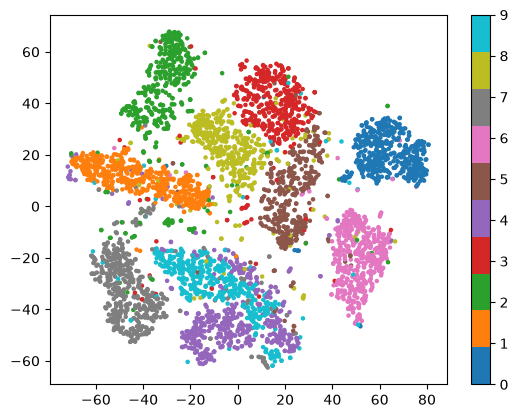

In [12]:
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=mnist.target[:5_000].astype(int), cmap="tab10", s=5)
plt.colorbar()
plt.show()

 Prueba a utilizar otros algoritmos de reducción de dimensionalidad como PCA, LLE o MDS y compara las visualizaciones resultantes (la opción de MDS puede que tarde un rato).

c:\Users\Raul\Documents\Ra\Clase - IABD\SAPA\IABD-SAPA-Aprendizaje_supervisado\.venv\Lib\site-packages\sklearn\manifold\_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(


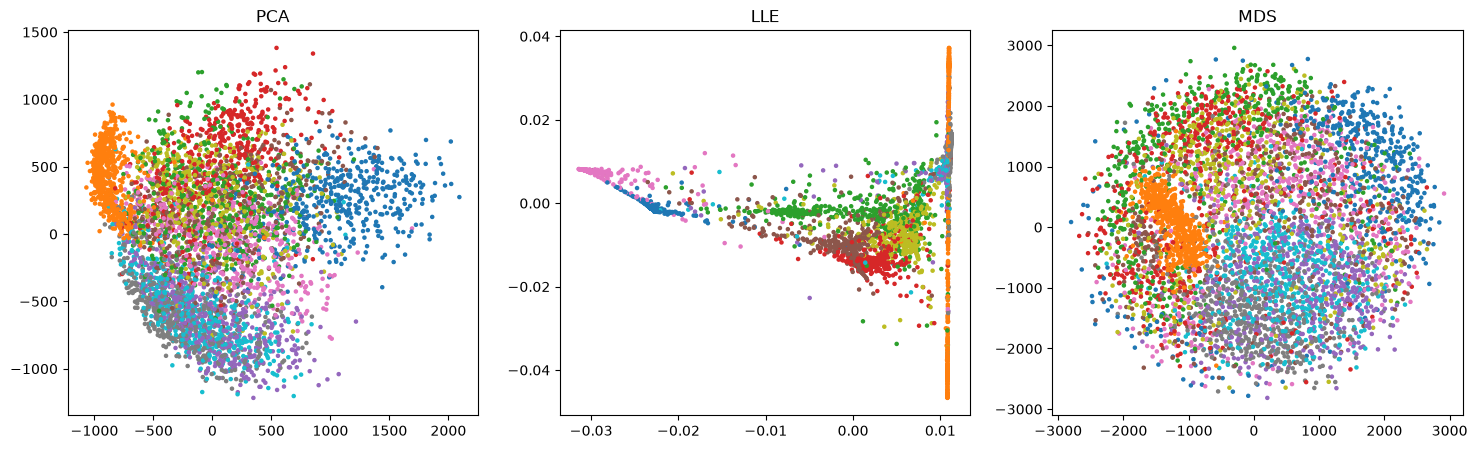

In [13]:
X = mnist.data[:5_000]
y = mnist.target[:5_000].astype(int)

algoritmos = {
    "PCA": PCA(n_components=2),
    "LLE": LocallyLinearEmbedding(n_components=2),
    "MDS": MDS(n_components=2),
}

plt.figure(figsize=(18, 5))
for i, (nombre, algoritmo) in enumerate(algoritmos.items(), start=1):
    X_2d = algoritmo.fit_transform(X)
    plt.subplot(1, 3, i)
    plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap="tab10", s=5)
    plt.title(nombre)
plt.show()

 Prueba ahora creando un pipeline que primero aplique PCA y luego MDS (lanzalo con tiempo).

c:\Users\Raul\Documents\Ra\Clase - IABD\SAPA\IABD-SAPA-Aprendizaje_supervisado\.venv\Lib\site-packages\sklearn\manifold\_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(


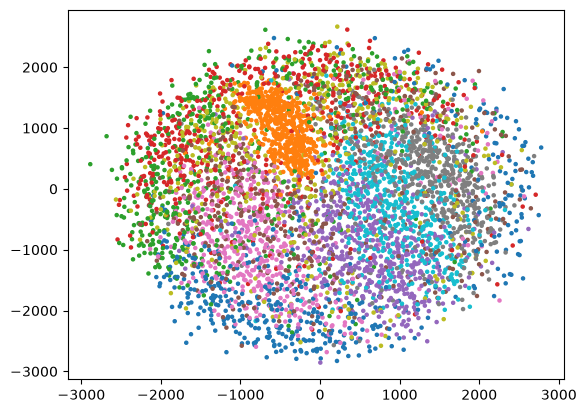

In [14]:
pca_mds = make_pipeline(PCA(n_components=0.95), MDS(n_components=2))

X_pca_mds = pca_mds.fit_transform(X)

plt.scatter(X_pca_mds[:, 0], X_pca_mds[:, 1], c=y, cmap="tab10", s=5)
plt.show()